# When does flu season actually start in Australia?

I'm using every lab-confirmed flu case reported in Australia from 2008 to 2024 to answer three questions:

- When does flu season start and peak in each state?
- Has that timing changed since COVID?
- Could you spot the start early enough to warn people?

**Data:** NNDSS public dataset, influenza (laboratory confirmed), Australian Centre for Disease Control. One row per case, extracted 28 May 2025.
Source: https://www.cdc.gov.au/resources/publications/nndss-dataset-influenza

**How the notebook is laid out**
1. Prepare the data
2. Check its quality
3. Answer five questions
4. Export tidy files for Power BI

Put the raw Excel file in `data/raw/` before running. The cleaned files land in `data/clean/`.

## 1. Data preparation

### 1.1 Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (11, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

RAW_FILE = Path("data/raw/nndss-public-dataset-influenza-laboratory-confirmed.xlsx")
CLEAN_DIR = Path("data/clean")
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

### 1.2 Load and stack the four sheets
Each sheet has a title in row 1, so the real header is row 2 (`header=1`). Loading takes a minute or two because there are about 2 million rows.

In [2]:
sheets = pd.ExcelFile(RAW_FILE).sheet_names
print("Sheets:", sheets)

frames = []
for s in sheets:
    df_s = pd.read_excel(RAW_FILE, sheet_name=s, header=1)
    df_s["source_sheet"] = s
    frames.append(df_s)

raw = pd.concat(frames, ignore_index=True)
print(f"Rows loaded: {len(raw):,}")
raw.head()

Sheets: ['2008-2015', '2016-2018', '2019-2021', '2022-2024']


Rows loaded: 1,974,685


,Week Ending (Friday),State,Age group,Sex,Indigenous status,Type/Subtype,source_sheet
0,2008-01-04,NT,00-04,MALE,Indigenous,Untyped,2008-2015
1,2008-01-04,NT,50-54,FEMALE,Indigenous,A(unsubtyped),2008-2015
2,2008-01-04,Qld,10-14,FEMALE,Non-Indigenous,A(H1N1),2008-2015
3,2008-01-04,Qld,15-19,FEMALE,Non-Indigenous,A(unsubtyped),2008-2015
4,2008-01-04,Qld,15-19,FEMALE,Non-Indigenous,B,2008-2015


### 1.3 Rename columns

In [3]:
raw.columns = [c.strip() for c in raw.columns]
print(raw.columns.tolist())

df = raw.rename(columns={
    raw.columns[0]: "week_ending",
    raw.columns[1]: "state",
    raw.columns[2]: "age_group",
    raw.columns[3]: "sex",
    raw.columns[4]: "indigenous_status",
    raw.columns[5]: "flu_subtype",
})
df.dtypes

['Week Ending (Friday)', 'State', 'Age  group', 'Sex', 'Indigenous status', 'Type/Subtype', 'source_sheet']


week_ending          datetime64[us]
state                           str
age_group                       str
sex                             str
indigenous_status               str
flu_subtype                     str
source_sheet                    str
dtype: object

### 1.4 Fix data types and drop empty rows

In [4]:
df["week_ending"] = pd.to_datetime(df["week_ending"], errors="coerce")

before = len(df)
df = df.dropna(subset=["week_ending"])
print(f"Dropped {before - len(df):,} rows with no date")

for col in ["state", "age_group", "sex", "indigenous_status", "flu_subtype"]:
    df[col] = df[col].astype("string").str.strip()

df.dtypes

Dropped 0 rows with no date


week_ending          datetime64[us]
state                        string
age_group                    string
sex                          string
indigenous_status            string
flu_subtype                  string
source_sheet                    str
dtype: object

### 1.5 Look at the raw values before cleaning

In [5]:
for col in ["state", "age_group", "sex", "indigenous_status", "flu_subtype"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).to_string(), "\n")

--- state ---
state
NSW    752888
Qld    472599
Vic    364842
SA     186194
WA     125479
ACT     26040
Tas     24635
NT      22008 

--- age_group ---
age_group
05-09    267048
00-04    231914
10-14    169166
15-19    129781
35-39    128935
30-34    123540
40-44    112449
25-29    107311
20-24    102312
45-49     93446
50-54     85782
55-59     80352
60-64     74758
65-69     62357
85+       60015
70-74     54685
75-79     48854
80-84     41747
<NA>        233 

--- sex ---
sex
FEMALE        1050123
MALE           920257
<NA>             2714
NOT STATED       1577
X                  14 

--- indigenous_status ---
indigenous_status
Non-Indigenous    813262
Not available     645062
Unknown           443638
Indigenous         72723 

--- flu_subtype ---
flu_subtype
A(unsubtyped)    1340129
B                 416270
A(H1N1)pdm09       90828
A(H3N2)            80003
Untyped            37914
A(H1N1)             6884
A and B             2620
C                     37 



### 1.6 Clean the category values
- **Sex:** blank, NOT STATED and X become `Unknown`.
- **Indigenous status:** Not available and Unknown become `Unknown`.
- **Flu type:** keep the detailed subtype, and add a broad `flu_type` column (A, B, Other/Untyped).
- **Age group:** add a broad band for the dashboard.

In [6]:
df["sex"] = (df["sex"].str.upper()
             .map({"FEMALE": "Female", "MALE": "Male"})
             .fillna("Unknown"))

df["indigenous_status"] = df["indigenous_status"].replace({"Not available": "Unknown"}).fillna("Unknown")

df["flu_subtype"] = df["flu_subtype"].fillna("Untyped")

def broad_type(x):
    if x.startswith("A and B"):
        return "Other/Untyped"
    if x.startswith("A"):
        return "A"
    if x == "B":
        return "B"
    return "Other/Untyped"

df["flu_type"] = df["flu_subtype"].map(broad_type)

df["age_group"] = df["age_group"].fillna("Unknown")

def broad_age(a):
    if a == "Unknown":
        return "Unknown"
    start = 85 if a == "85+" else int(a.split("-")[0])
    if start < 5:
        return "0-4"
    if start < 20:
        return "5-19"
    if start < 65:
        return "20-64"
    return "65+"

df["age_band_broad"] = df["age_group"].map(broad_age)

for col in ["sex", "indigenous_status", "flu_type", "age_band_broad"]:
    print(df[col].value_counts().to_string(), "\n")

sex
Female     1050123
Male        920257
Unknown       4305 

indigenous_status
Unknown           1088700
Non-Indigenous     813262
Indigenous          72723 



flu_type
A                1517844
B                 416270
Other/Untyped      40571 

age_band_broad
20-64      908885
5-19       565995
65+        267658
0-4        231914
Unknown       233 



### 1.7 Add date columns
**Season rule:** Australian flu season runs through the middle of the year, so the calendar year works as the season year. The one exception is the week ending 3 Jan 2025: it mostly covers late December 2024, so it is assigned to the 2024 season. Rule used: `season_year` = the year of the week's start date (week ending minus 6 days).

In [7]:
df["week_start"] = df["week_ending"] - pd.Timedelta(days=6)
df["season_year"] = df["week_start"].dt.year
# The first week (ending 4 Jan 2008) starts on 29 Dec 2007; keep it in the 2008 season
df.loc[df["season_year"] < 2008, "season_year"] = 2008
df["year"] = df["week_ending"].dt.year
df["month"] = df["week_ending"].dt.month
df["iso_week"] = df["week_ending"].dt.isocalendar().week.astype(int)

print(df.groupby("season_year").size().to_string())

season_year
2008      9181
2009     59032
2010     13417
2011     27285
2012     44575
2013     28335
2014     67624
2015    100523
2016     91340
2017    251286
2018     59123
2019    313088
2020     20938
2021       749
2022    234312
2023    290027
2024    363850


## 2. Data quality checks

In [8]:
print(f"Total cases: {len(df):,}")
print(f"Date range: {df['week_ending'].min().date()} to {df['week_ending'].max().date()}")
print()
print("Nulls per column:")
print(df.isna().sum().to_string())
print()
dupes = df.duplicated(subset=["week_ending", "state", "age_group", "sex", "indigenous_status", "flu_subtype"]).sum()
print(f"Rows identical on every field: {dupes:,}")
print("Note: these are NOT errors. Two people of the same age, sex and state can get flu in the same week. There is no case ID, so true duplicates cannot be detected.")

Total cases: 1,974,685
Date range: 2008-01-04 to 2025-01-03

Nulls per column:


week_ending          0
state                0
age_group            0
sex                  0
indigenous_status    0
flu_subtype          0
source_sheet         0
flu_type             0
age_band_broad       0
week_start           0
season_year          0
year                 0
month                0
iso_week             0



Rows identical on every field: 1,654,095
Note: these are NOT errors. Two people of the same age, sex and state can get flu in the same week. There is no case ID, so true duplicates cannot be detected.


In [9]:
unknown_share = (df[["sex", "indigenous_status", "age_band_broad"]] == "Unknown").mean().mul(100).round(1)
print("% of rows marked Unknown:")
print(unknown_share.to_string())
print()
print("% of cases with no subtype (A unsubtyped or Untyped):",
      round(df["flu_subtype"].isin(["A(unsubtyped)", "Untyped"]).mean() * 100, 1))

% of rows marked Unknown:
sex                   0.2
indigenous_status    55.1
age_band_broad        0.0

% of cases with no subtype (A unsubtyped or Untyped): 69.8


**Weeks with zero cases per state.** A state with zero cases in a winter week would be suspicious (possible reporting gap).

In [10]:
all_weeks = pd.date_range(df["week_ending"].min(), df["week_ending"].max(), freq="W-FRI")
grid = pd.MultiIndex.from_product([all_weeks, sorted(df["state"].dropna().unique())], names=["week_ending", "state"])
weekly_state = df.groupby(["week_ending", "state"]).size().reindex(grid, fill_value=0).rename("cases").reset_index()

zero = weekly_state[weekly_state["cases"] == 0]
print(f"State-weeks with zero cases: {len(zero):,} of {len(weekly_state):,}")
winter_zero = zero[zero["week_ending"].dt.month.isin([6, 7, 8])]
print("Zero-case winter (Jun-Aug) weeks by state and year:")
print(winter_zero.groupby([winter_zero['week_ending'].dt.year, 'state']).size().unstack(fill_value=0))

State-weeks with zero cases: 570 of 7,104
Zero-case winter (Jun-Aug) weeks by state and year:
state        ACT  NSW  NT  SA  Tas  Vic  WA
week_ending                                
2008           0    0   4   2    1    0   0
2010           1    0   2   0    8    0   0
2011           0    0   2   0    0    0   0
2013           0    0   1   0    0    0   0
2016           0    0   1   0    0    0   0
2018           0    0   3   0    0    0   0
2020           7    0  12   4    8    0   1
2021           9    2   9  11    3    4   3


**Quality summary**
- No nulls remain after cleaning. Total cases: 1,974,685.
- Indigenous status is Unknown for 55% of cases, so it is not used in the analysis.
- About 70% of cases have no subtype, so only the broad A vs B split is used.
- Many rows are identical on every field. That's expected (same week, state, age band and sex), not a duplication error.
- Zero-case winter weeks are mostly in 2020 and 2021 (COVID border closures). The rest are in small jurisdictions (NT, Tas) in early years. These look real, not reporting gaps.
- NT peaks are erratic (some fall in January or December). NT is tropical and has small numbers, so its flu pattern does not follow the southern winter. Treat NT results with caution.

## 3. Analysis

### Q1. How big is each season, and what happened during COVID?
**Caveat:** case counts depend on how many people get tested. Testing rose sharply after 2020, so recent years look bigger partly because more people were tested.

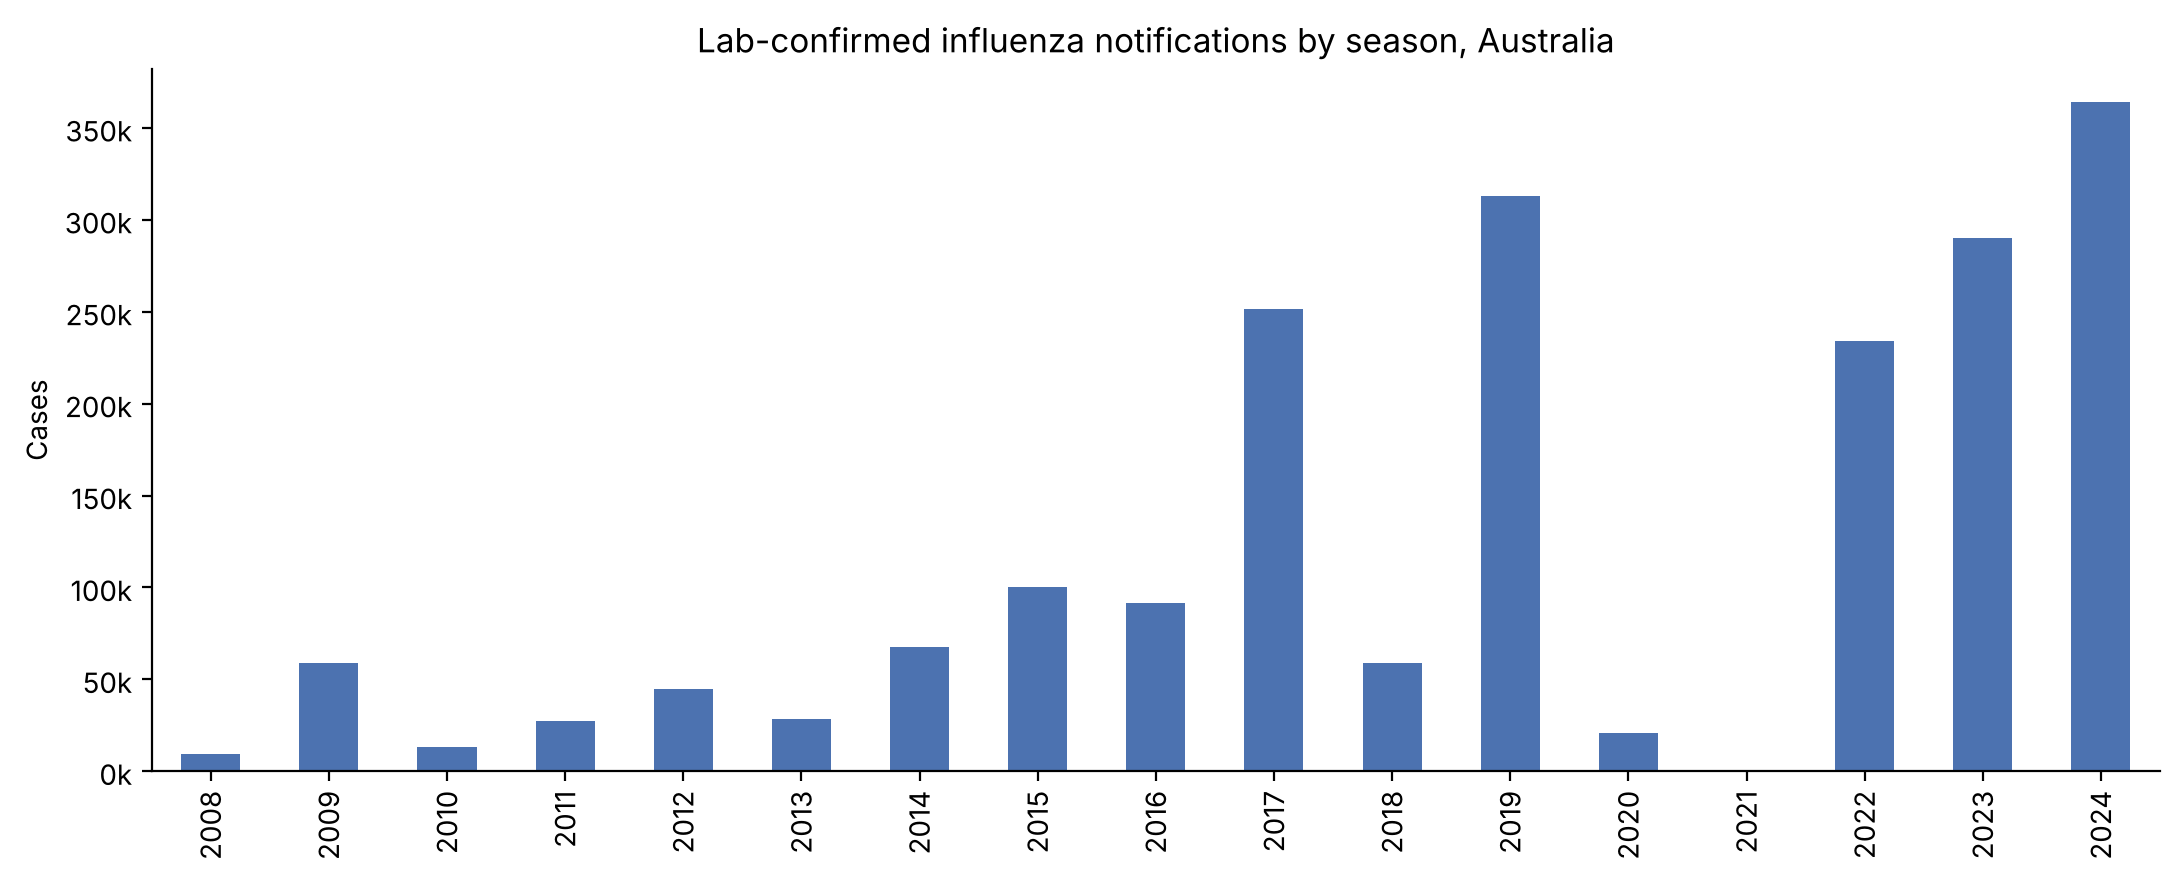

season_year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
cases,9181,59032,13417,27285,44575,28335,67624,100523,91340,251286,59123,313088,20938,749,234312,290027,363850


In [11]:
season_totals = df.groupby("season_year").size()
season_totals = season_totals[season_totals.index.to_series().between(2008, 2024)]

ax = season_totals.plot(kind="bar", color="#4C72B0")
ax.set_title("Lab-confirmed influenza notifications by season, Australia")
ax.set_xlabel("")
ax.set_ylabel("Cases")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
plt.tight_layout()
plt.show()

season_totals.to_frame("cases").T

### Q2. When does the season start and peak in each state?

In [12]:
weekly_state["season_year"] = (weekly_state["week_ending"] - pd.Timedelta(days=6)).dt.year.clip(lower=2008)
weekly_state["iso_week"] = weekly_state["week_ending"].dt.isocalendar().week.astype(int)

ws = weekly_state[(weekly_state["season_year"].between(2008, 2024)) & (~weekly_state["season_year"].isin([2020, 2021]))].copy()

peaks = (ws.loc[ws.groupby(["season_year", "state"])["cases"].idxmax()]
           [["season_year", "state", "week_ending", "iso_week", "cases"]]
           .rename(columns={"week_ending": "peak_week_ending", "iso_week": "peak_iso_week", "cases": "peak_cases"}))

peak_pivot = peaks.pivot(index="season_year", columns="state", values="peak_iso_week")
print("Peak week of the year (ISO week) by state. 2020 and 2021 excluded (no real season).")
peak_pivot

Peak week of the year (ISO week) by state. 2020 and 2021 excluded (no real season).


state,ACT,NSW,NT,Qld,SA,Tas,Vic,WA
season_year,,,,,,,,
2008,37,36,39,35,39,36,35,37
2009,29,28,28,30,32,29,23,32
2010,36,36,38,36,38,38,35,38
2011,29,29,10,31,31,33,37,34
2012,28,28,28,33,27,29,32,29
2013,35,35,1,35,35,39,35,38
2014,34,34,35,33,35,34,34,34
2015,34,34,38,34,34,35,35,33
2016,34,35,39,35,37,35,35,35


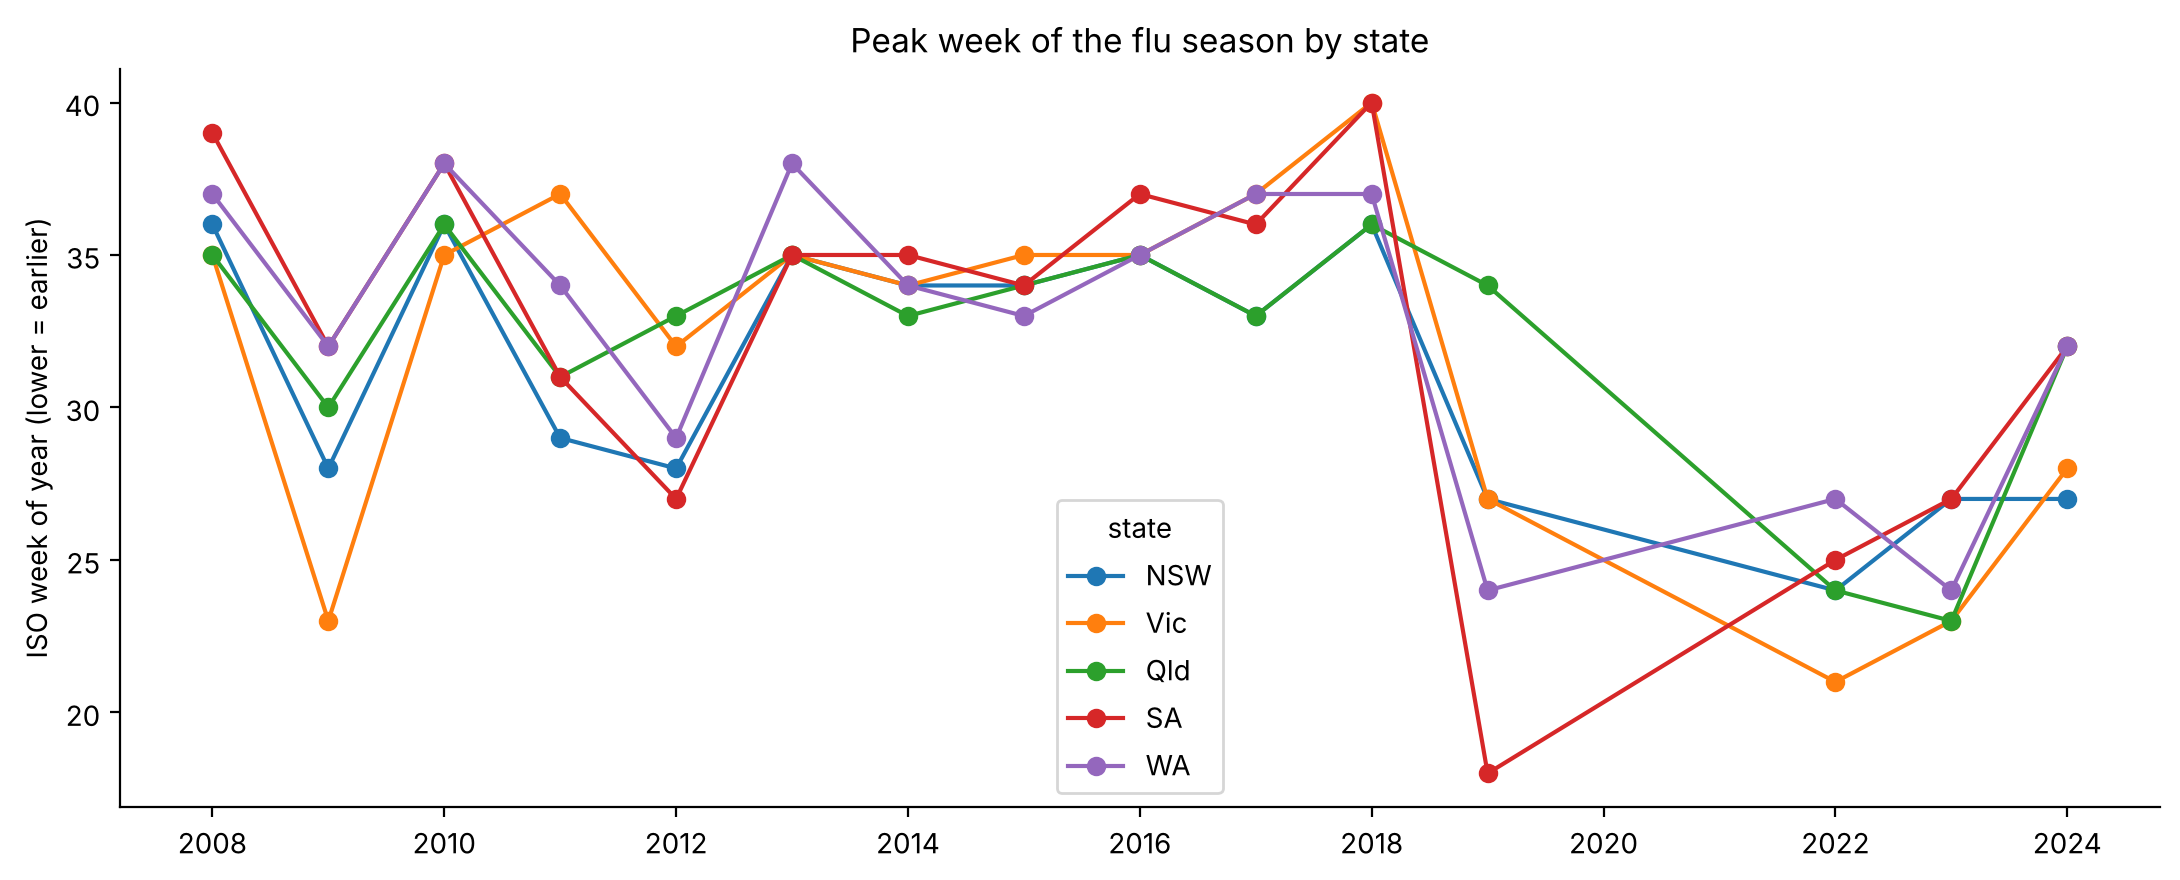

Median peak week by state:
state
ACT    33.0
NSW    33.0
Qld    33.0
SA     34.0
WA     34.0
Tas    34.0
NT     35.0
Vic    35.0


In [13]:
ax = peak_pivot[["NSW", "Vic", "Qld", "SA", "WA"]].plot(marker="o")
ax.set_title("Peak week of the flu season by state")
ax.set_ylabel("ISO week of year (lower = earlier)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

print("Median peak week by state:")
print(peak_pivot.median().sort_values().to_string())

**Season onset rule (used for early warning):**
1. Baseline = median weekly cases for that state in weeks 1 to 13 (Jan to Mar) of the same season.
2. Onset = the first week from week 14 onward where cases are at least **3x baseline** for **2 weeks in a row**.

This is a simple, explainable rule. It can be tuned later.

In [14]:
def find_onset(g, multiplier=3, run=2):
    g = g.sort_values("week_ending")
    base = g.loc[g["iso_week"] <= 13, "cases"].median()
    base = max(base, 1)
    after = g[g["iso_week"] >= 14].copy()
    above = after["cases"] >= multiplier * base
    streak = above.rolling(run).sum() == run
    if not streak.any():
        return pd.Series({"baseline": base, "onset_week_ending": pd.NaT, "onset_iso_week": np.nan})
    first = streak.idxmax()
    pos = after.index.get_loc(first) - (run - 1)
    row = after.iloc[pos]
    return pd.Series({"baseline": base, "onset_week_ending": row["week_ending"], "onset_iso_week": row["iso_week"]})

onsets = ws.groupby(["season_year", "state"]).apply(find_onset, include_groups=False).reset_index()
season_summary = onsets.merge(peaks, on=["season_year", "state"])
season_summary["weeks_onset_to_peak"] = season_summary["peak_iso_week"] - season_summary["onset_iso_week"]

season_summary.pivot(index="season_year", columns="state", values="onset_iso_week")

state,ACT,NSW,NT,Qld,SA,Tas,Vic,WA
season_year,,,,,,,,
2008,27.0,18.0,33.0,30.0,23.0,32.0,14.0,30.0
2009,18.0,21.0,18.0,18.0,15.0,21.0,18.0,18.0
2010,29.0,31.0,25.0,29.0,25.0,35.0,25.0,22.0
2011,22.0,23.0,NaN,25.0,20.0,15.0,29.0,28.0
2012,21.0,21.0,14.0,21.0,21.0,24.0,23.0,23.0
2013,25.0,26.0,NaN,33.0,27.0,28.0,26.0,31.0
2014,27.0,26.0,34.0,29.0,27.0,25.0,26.0,27.0
2015,27.0,25.0,30.0,26.0,23.0,14.0,24.0,25.0
2016,28.0,27.0,33.0,30.0,31.0,30.0,27.0,26.0


### Q3. Early warning: how much notice does onset give before the peak?

Weeks from onset signal to peak, by state (median, min, max):
       median  min   max  count
state                          
NT        6.0  0.0  14.0     12
Qld       6.5  2.0  12.0     14
NSW       7.0  2.0  18.0     15
ACT       7.0  6.0  13.0     14
WA        7.0  5.0  16.0     15
Vic       8.0  4.0  21.0     15
Tas       9.0  3.0  21.0     15
SA       11.0  2.0  17.0     15


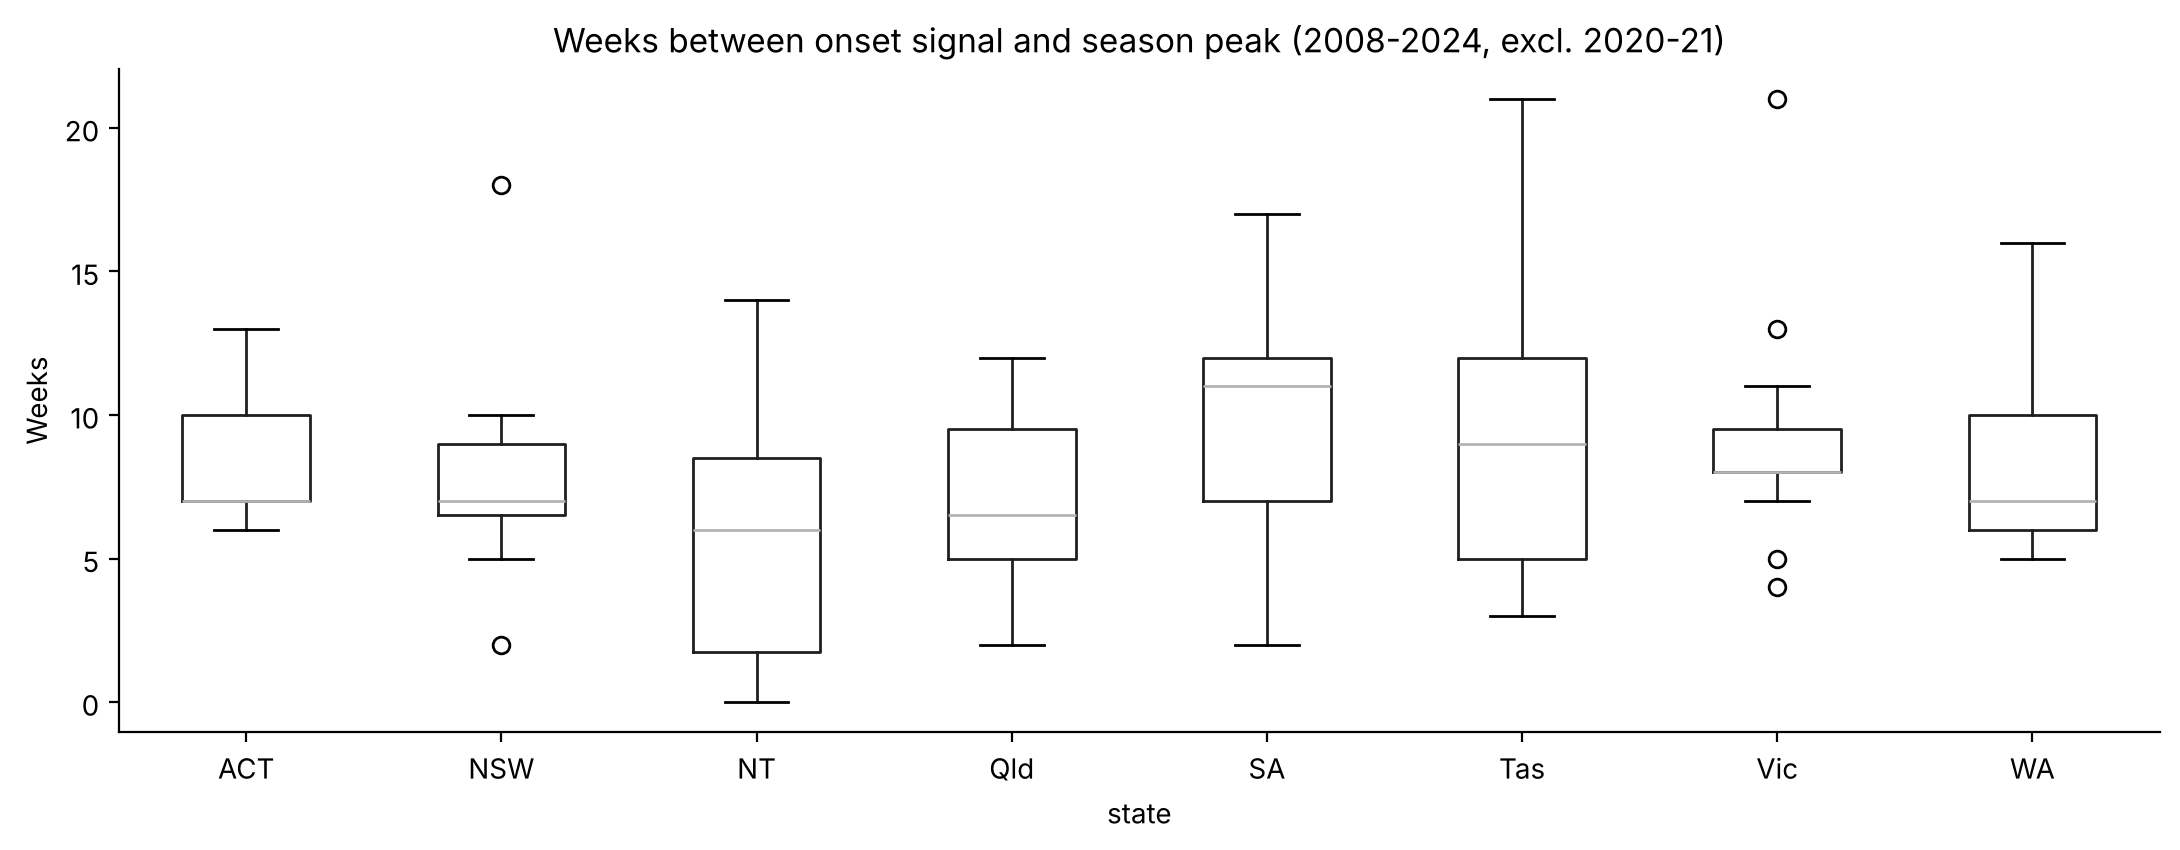

In [15]:
lead = season_summary.dropna(subset=["weeks_onset_to_peak"])
lead = lead[lead["weeks_onset_to_peak"] >= 0]

print("Weeks from onset signal to peak, by state (median, min, max):")
print(lead.groupby("state")["weeks_onset_to_peak"].agg(["median", "min", "max", "count"]).sort_values("median").to_string())

ax = lead.boxplot(column="weeks_onset_to_peak", by="state", grid=False)
plt.suptitle("")
ax.set_title("Weeks between onset signal and season peak (2008-2024, excl. 2020-21)")
ax.set_ylabel("Weeks")
plt.tight_layout()
plt.show()

### Q4. Who is affected? Age and sex

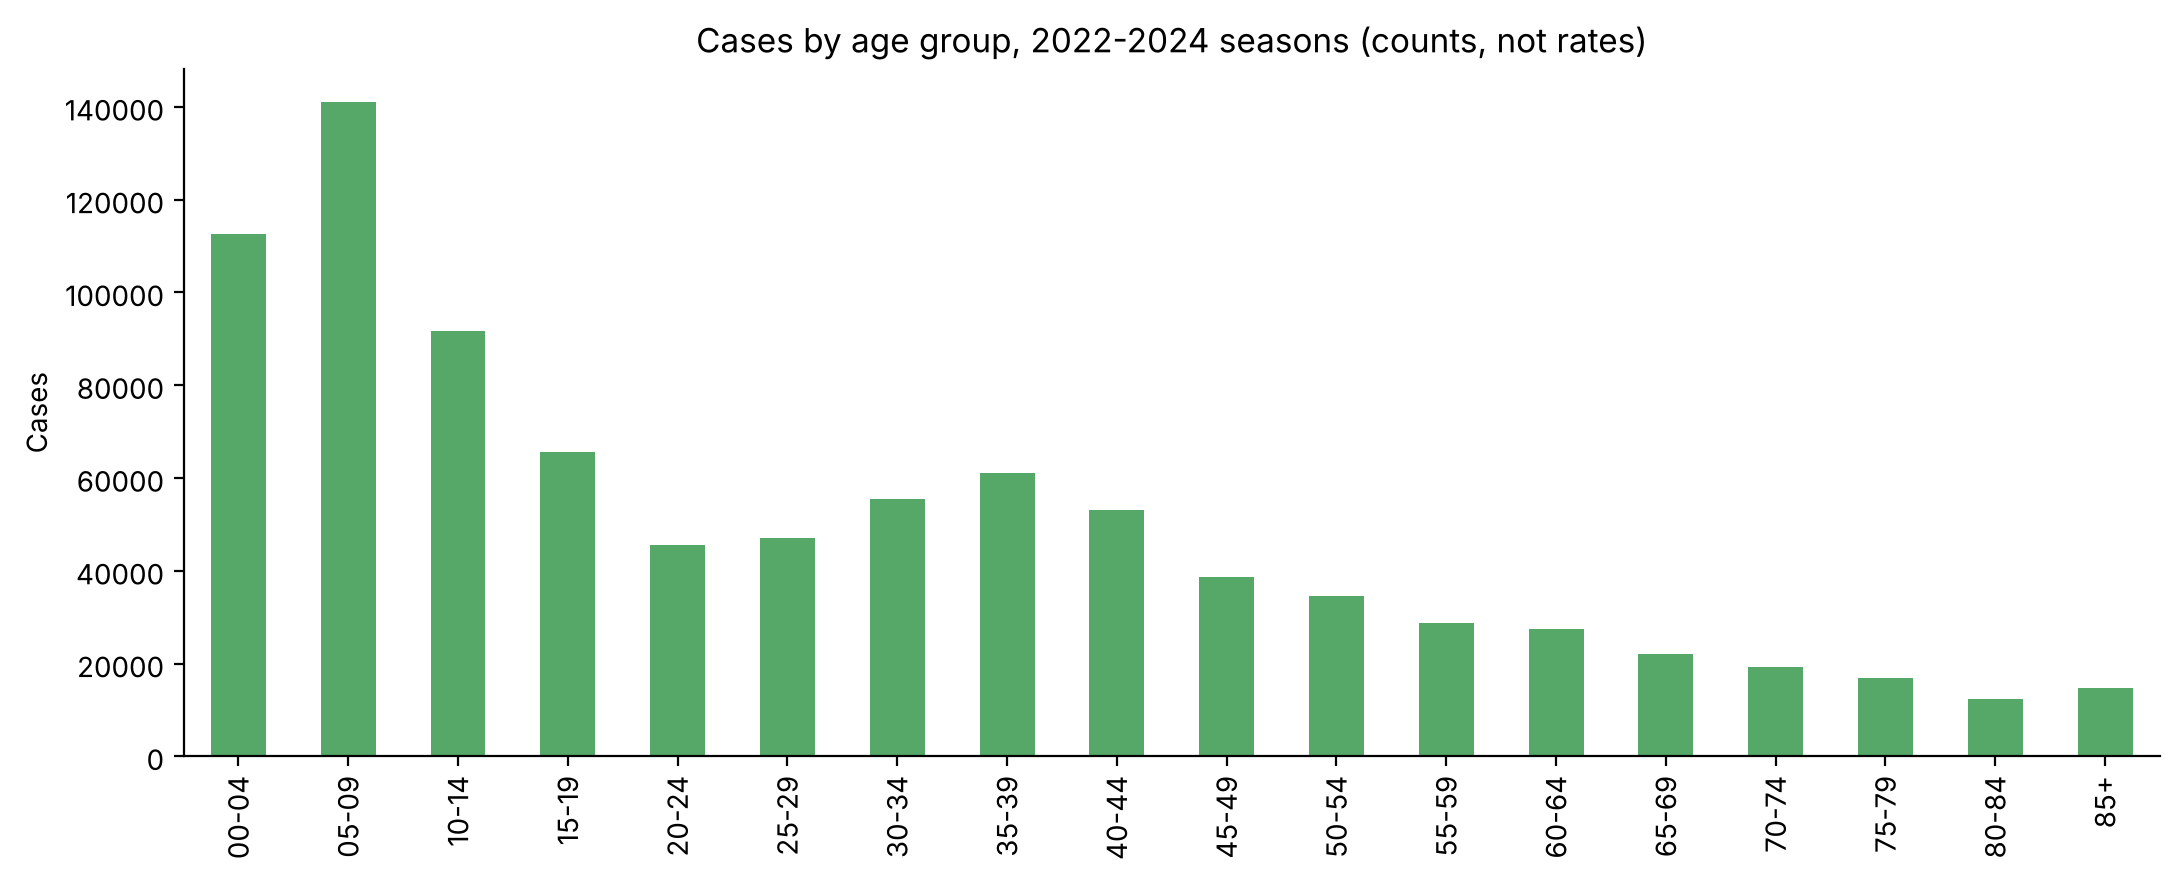

Share of cases by broad age band, 2022-2024 (%):
age_band_broad
0-4        12.7
5-19       33.6
20-64      44.1
65+         9.6
Unknown     0.0

Share by sex (%):
sex
Female     52.6
Male       47.3
Unknown     0.1


In [16]:
recent = df[df["season_year"].between(2022, 2024)]

age_order = sorted([a for a in df["age_group"].unique() if a != "Unknown"], key=lambda a: 85 if a == "85+" else int(a.split("-")[0]))
age_counts = recent["age_group"].value_counts().reindex(age_order)

ax = age_counts.plot(kind="bar", color="#55A868")
ax.set_title("Cases by age group, 2022-2024 seasons (counts, not rates)")
ax.set_xlabel("")
ax.set_ylabel("Cases")
plt.tight_layout()
plt.show()

share = (recent["age_band_broad"].value_counts(normalize=True).mul(100).round(1)
         .reindex(["0-4", "5-19", "20-64", "65+", "Unknown"]))
print("Share of cases by broad age band, 2022-2024 (%):")
print(share.to_string())
print()
print("Share by sex (%):")
print(recent["sex"].value_counts(normalize=True).mul(100).round(1).to_string())

**Caveat:** these are counts. The 20-64 band covers far more people than 0-4, so a fair comparison needs ABS population figures to calculate rates per 100,000. Children are tested more often than adults, which also inflates their counts.

### Q5. Which flu type leads each season?

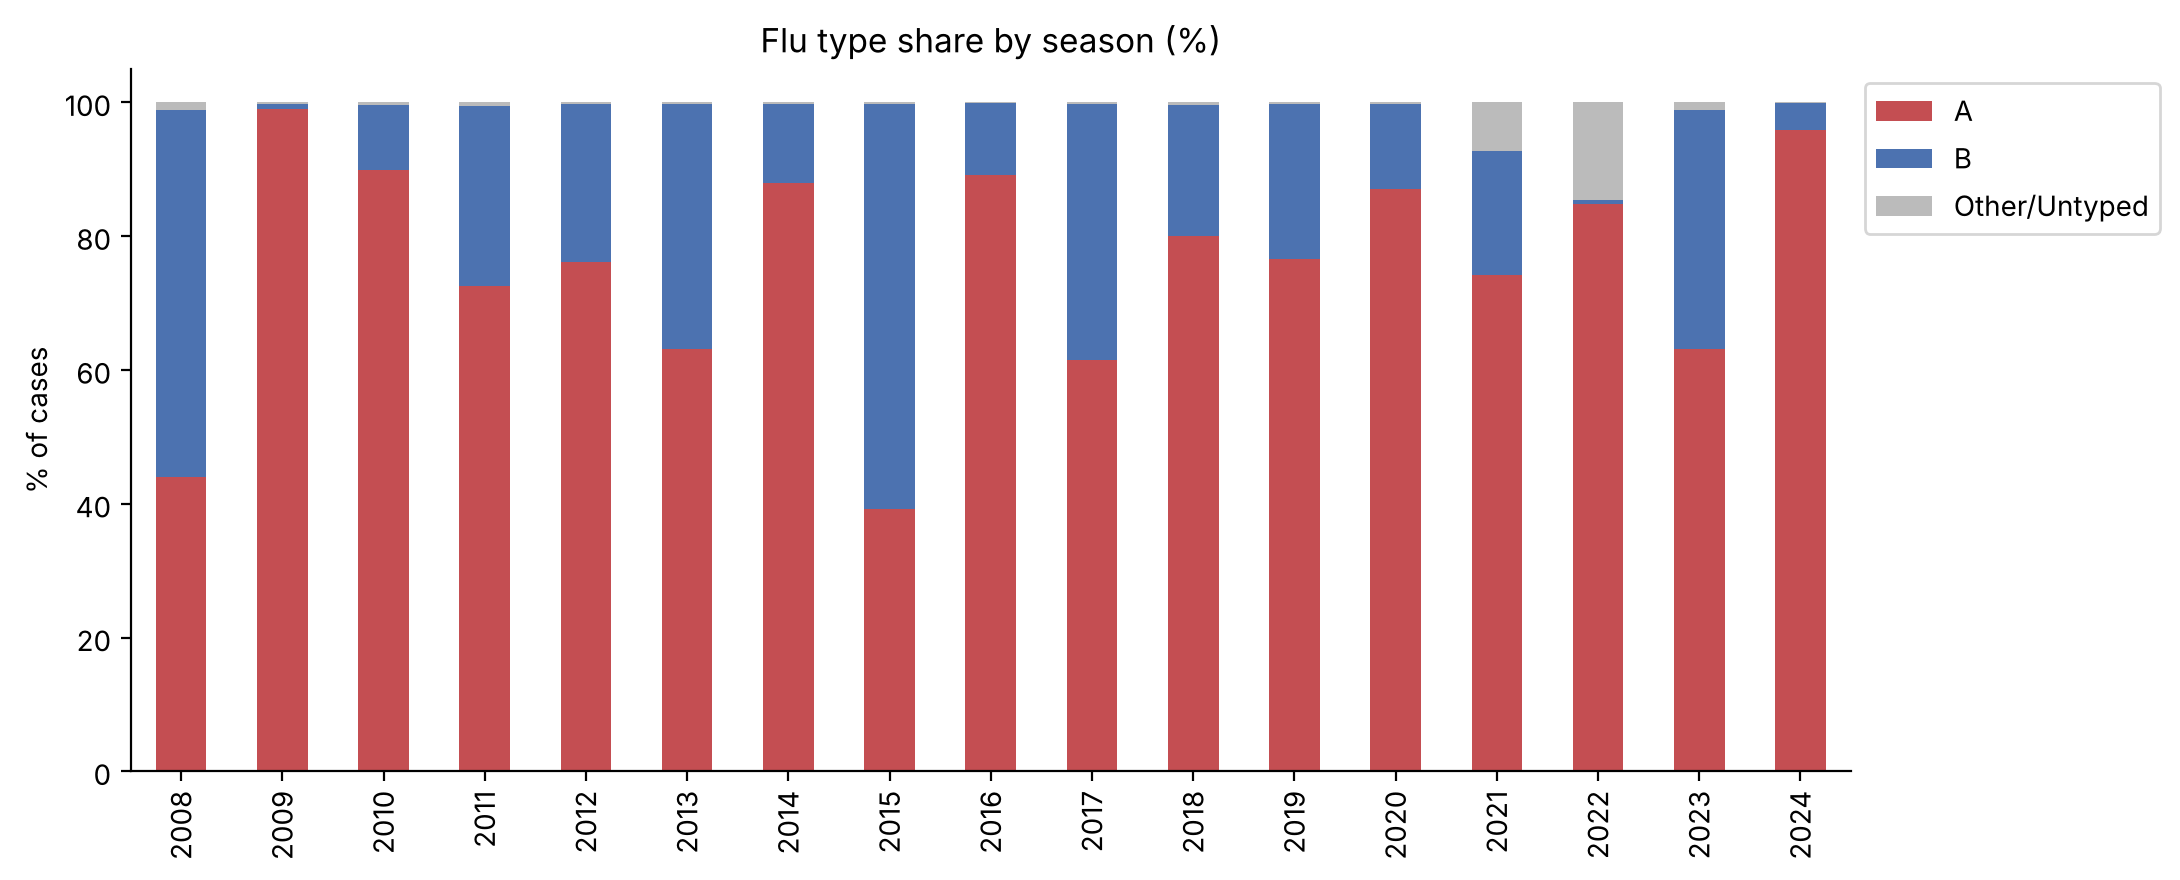

flu_type,A,B,Other/Untyped
season_year,,,
2008,44.0,54.9,1.1
2009,99.0,0.8,0.2
2010,89.8,9.7,0.5
2011,72.6,26.8,0.6
2012,76.1,23.7,0.2
2013,63.1,36.6,0.3
2014,87.9,11.9,0.2
2015,39.3,60.5,0.2
2016,89.1,10.7,0.1


In [17]:
type_season = (df[df["season_year"].between(2008, 2024)]
               .groupby(["season_year", "flu_type"]).size()
               .unstack(fill_value=0))
type_share = type_season.div(type_season.sum(axis=1), axis=0).mul(100)

ax = type_share[["A", "B", "Other/Untyped"]].plot(kind="bar", stacked=True, color=["#C44E52", "#4C72B0", "#BBBBBB"])
ax.set_title("Flu type share by season (%)")
ax.set_ylabel("% of cases")
ax.set_xlabel("")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

type_share.round(1)

### Seasonal shape: all years on one chart

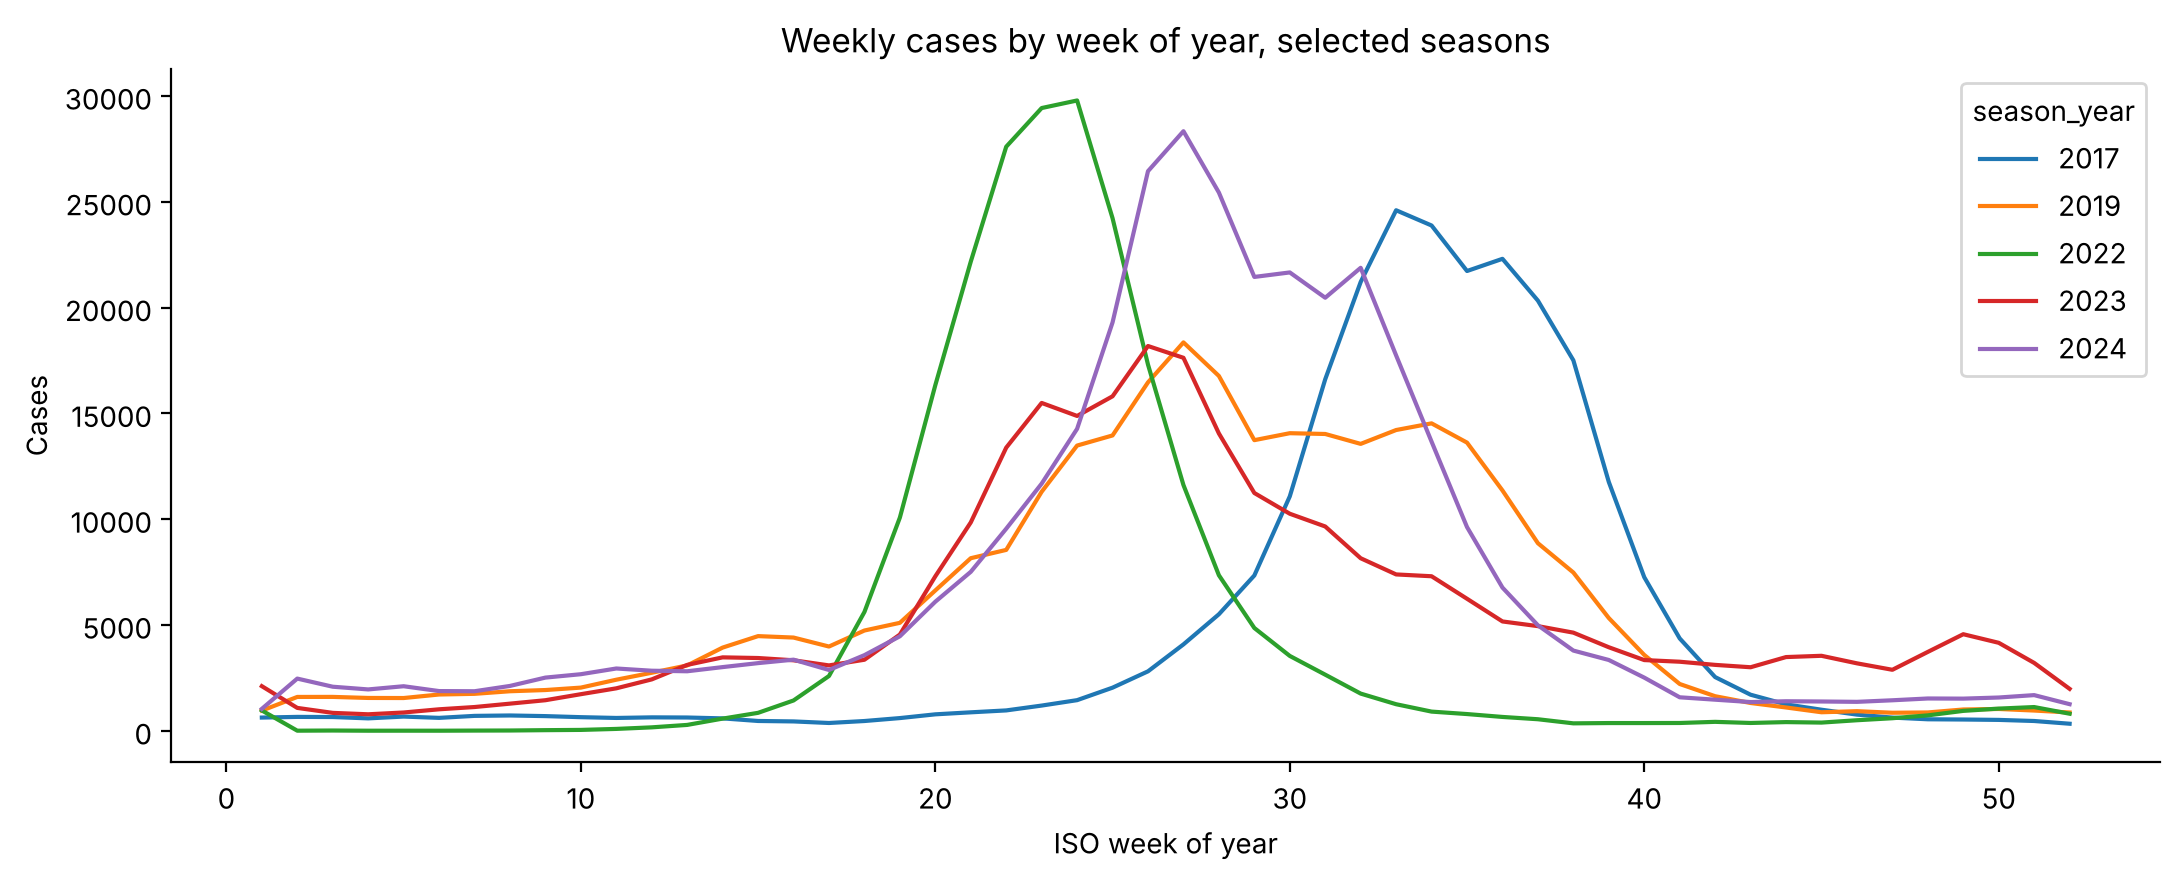

In [18]:
nat = df.groupby(["season_year", "iso_week"]).size().rename("cases").reset_index()
pivot = nat[nat["season_year"].isin([2017, 2019, 2022, 2023, 2024])].pivot(index="iso_week", columns="season_year", values="cases")

ax = pivot.plot()
ax.set_title("Weekly cases by week of year, selected seasons")
ax.set_xlabel("ISO week of year")
ax.set_ylabel("Cases")
plt.tight_layout()
plt.show()

## Key findings
1. **Season size:** notifications swing hugely by year. Big seasons were 2017 (251k) and 2019 (313k). COVID wiped out 2020 (21k) and 2021 (under 1k). 2024 was the highest on record (364k), but part of the post-COVID rise reflects much more testing, so it does not prove 2024 was the most severe season.
2. **Timing:** before COVID, seasons typically peaked around ISO week 33 to 35 (mid to late August). Since 2022 seasons have started and peaked earlier: peaks moved to roughly weeks 21 to 32 (late May to early August). The southern states (NSW, Vic, SA, ACT, Tas) move broadly together. NT does not follow the winter pattern.
3. **Early warning lead time:** using the 3x baseline rule, the onset signal fires a median of about 6 to 11 weeks before the peak, depending on the state (shortest NT and Qld, longest SA). That is enough notice for an app alert to be useful.
4. **Who is affected (counts):** in 2022 to 2024, people aged 5 to 19 made up about a third of cases, and children under 5 about 13%. Adults 20 to 64 had the largest share (44%), but they are also the largest population group. Women were slightly more of the cases (53%). Rates per 100,000 are needed before claiming any group is at higher risk.
5. **Flu type:** influenza A dominates most seasons. B led in 2008 and 2015 and was a large share in 2013, 2017 and 2023. 2024 was almost all A (96%).

**Limitations of the onset rule:** in 2022 the baseline (Jan to Mar) was close to zero after two years with almost no flu, so onset fired at the first allowed week (week 14) in every state. The rule needs a minimum baseline, or a baseline from previous years, before it could be used in a real alert.

**So what?**
- A state-level "flu season is starting" alert is realistic. The signal appears weeks before the peak, so users would get real notice.
- The alert can't be a fixed calendar date. Season timing has shifted earlier since 2022, so it has to be driven by the data each year.
- The first data limit to fix is the lack of rates. Joining ABS population data would show who is most at risk, not just who gets tested most.

## 4. Export for Power BI
Three files:
1. `flu_cases_agg.csv`: the fact table. Cases grouped by every column with a `case_count`, much smaller than 2 million rows.
2. `flu_weekly_state.csv`: weekly cases per state, including zero weeks (needed for clean line charts and rolling averages).
3. `flu_season_summary.csv`: onset week, peak week and lead time per state and season.

In [19]:
group_cols = ["week_ending", "season_year", "year", "month", "iso_week", "state",
              "age_group", "age_band_broad", "sex", "indigenous_status", "flu_type", "flu_subtype"]

fact = df.groupby(group_cols, dropna=False).size().rename("case_count").reset_index()
fact.to_csv(CLEAN_DIR / "flu_cases_agg.csv", index=False)

weekly_state.to_csv(CLEAN_DIR / "flu_weekly_state.csv", index=False)
season_summary.to_csv(CLEAN_DIR / "flu_season_summary.csv", index=False)

print(f"flu_cases_agg.csv: {len(fact):,} rows (total cases {fact['case_count'].sum():,})")
print(f"flu_weekly_state.csv: {len(weekly_state):,} rows")
print(f"flu_season_summary.csv: {len(season_summary):,} rows")
assert fact["case_count"].sum() == len(df), "Case total does not match"
print("Check passed: exported case total matches the cleaned data.")

flu_cases_agg.csv: 320,590 rows (total cases 1,974,685)
flu_weekly_state.csv: 7,104 rows
flu_season_summary.csv: 120 rows
Check passed: exported case total matches the cleaned data.
